/var/folders/nt/g3g_mp4d0cn2phh32qchfyf80000gn/T/ipykernel_10671/3146791256.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  binarised_data[columns_for_binarising] = binarised_data[columns_for_binarising].clip(0,1).astype(bool)
/var/folders/nt/g3g_mp4d0cn2phh32qchfyf80000gn/T/ipykernel_10671/3146791256.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  binarised_data.rename(columns=rename_map, inplace=True)
/var/folders/nt/g3g_mp4d0cn2phh32qchfyf80000gn/T/ipykernel_10671/3146791256.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a s

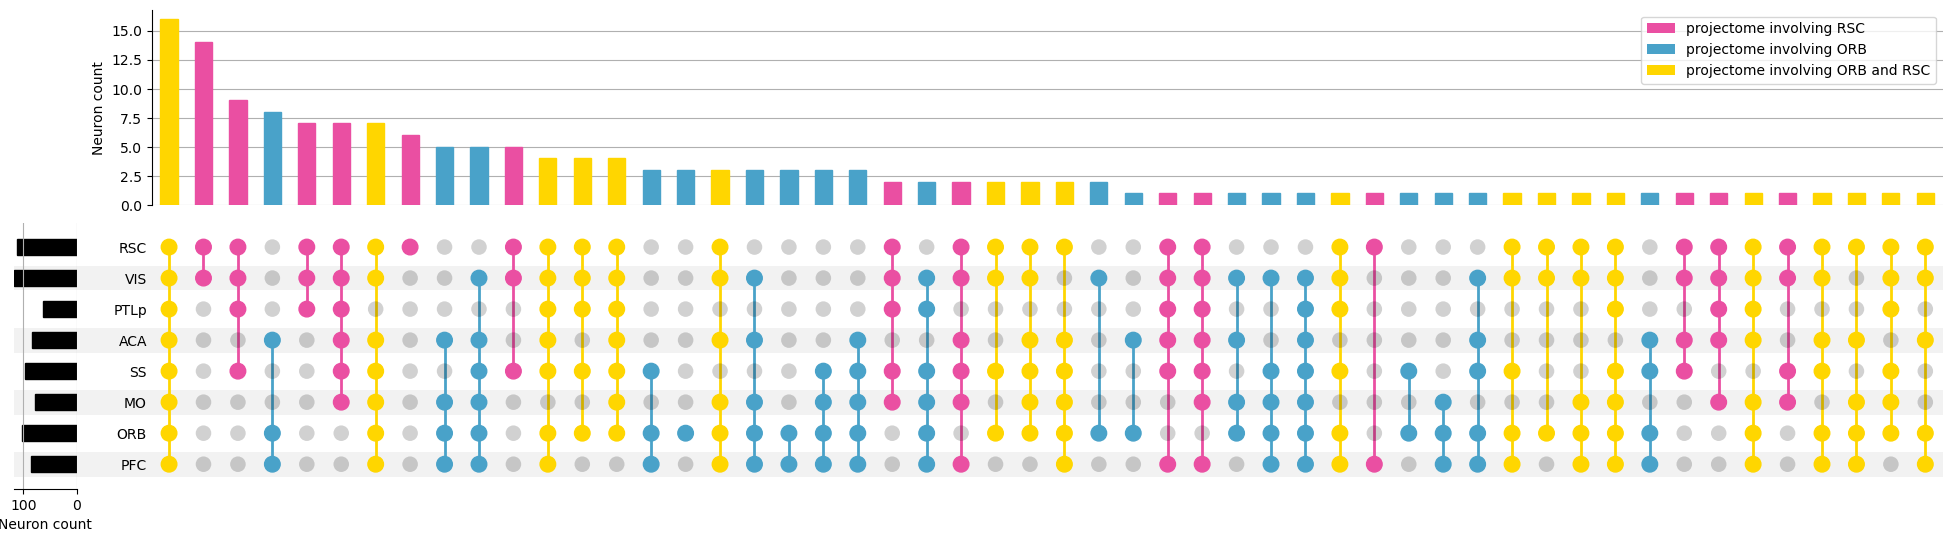

In [ ]:

from upsetplot import plot, from_indicators
from upsetplot import UpSet, generate_counts
import pandas as pd
import matplotlib.pyplot as plt
import os

path = str(os.getcwd())

areas = ["PFC","ORB",  "MO","SS","ACA",  "PTLp", "VIS",  "RSP"]

filtered_rsp_orb_only_data = pd.read_csv(f"{path}/master_detailed_comment.csv")

columns_for_binarising = [f"{area}_endpoint" for area in areas if f"{area}_endpoint" in filtered_rsp_orb_only_data.columns]


binarised_data = filtered_rsp_orb_only_data[columns_for_binarising + ["proj"]]
binarised_data[columns_for_binarising] = binarised_data[columns_for_binarising].clip(0,1).astype(bool)
rename_map = {col: col.replace("_endpoint", "") for col in columns_for_binarising}
binarised_data.rename(columns=rename_map, inplace=True)
binarised_data.rename(columns={"RSP":"RSC"},inplace = True)
areas = binarised_data.columns.drop("proj")


# create an upset plot
series = from_indicators(
    indicators=areas,  
    data=binarised_data
)

upset = UpSet(series, sort_by = "cardinality", facecolor="black", sort_categories_by="input")
upset.style_subsets(present=["RSC"], facecolor="#EA4FA2",  label="projectome involving RSC")
upset.style_subsets(present=["ORB"], facecolor="#49A2C9",  label="projectome involving ORB")
upset.style_subsets(present=["ORB", "RSC"], facecolor="#FFD600",  label="projectome involving ORB and RSC")
figure = upset.plot()
figure["intersections"].set_ylabel("Neuron count")
figure["totals"].set_xlabel("Neuron count")


plt.savefig(f'{path}/projectome_plot.svg')

